# 🛡️ SOC Threat Hunting & Behavioral Analysis  (v4)
### Supervised alert triage + Unsupervised anomaly detection + SOC-aware threshold optimization

**Pipeline overview**

| Stage | What it does | Why it matters in a SOC |
|---|---|---|
| 1. Data adapter | Loads *UNSW-NB15* (train → test). Swap to *CERT* with one config switch | Same pipeline, different data |
| 2. Supervised engine | LightGBM + Random Forest, 3-tier triage (auto-close / analyst review / auto-escalate) | Cuts false positives and analyst workload |
| 3. Unsupervised engine | Isolation Forest + Autoencoder trained on **normal traffic only** | Catches novel / polymorphic behaviour that has no labels |
| 4. Threshold optimization | Cost-based, F-beta, precision-floor, alert-budget — **evaluated at a realistic attack rate** | A SOC cares about *analyst hours* and *missed attacks*, not accuracy |
| 5. Hybrid + zero-day test | Blend both engines; compare everything at **equal false-positive rates** | Shows whether the system can see attacks it never trained on |
| 6. Explainability + export | Per-alert top contributing features, saved models | Analysts need to know *why* an alert fired |

**What is new in v4 (fixes from the first run)**
* UNSW-NB15 is ~55-68 % attacks, a real SOC sees well under 1 %. Thresholds and metrics are now computed at a **realistic prevalence** (`REAL_PREVALENCE`) by re-weighting benign events, so precision and alert volume mean something.
* Supervised scores use LightGBM **log-odds**, so there are no ties at probability 1.0 (the alert-budget strategy now works).
* All models are compared at **fixed false-positive rates** (0.1 %, 1 %, 5 %), including per-attack-family and zero-day results.
* The hybrid score is built from **benign-normalised z-scores** and the weight search is honest when anomaly scores add nothing.
* New: cost / prevalence sensitivity table.

**Data discipline:** `training-set` → split into *train* and *validation* (early stopping + threshold tuning). `testing-set` is only used for the final evaluation.

## 0. Setup
Uncomment the install line if you are missing packages.

In [1]:
# !pip install lightgbm scikit-learn pandas numpy matplotlib joblib

import warnings, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")          # no automatic image/png output (avoids the VS Code renderer error)
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve,
                             confusion_matrix, roc_curve)
import lightgbm as lgb

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
plt.rcParams.update({"figure.figsize": (7, 4.5), "axes.grid": True, "grid.alpha": 0.3})
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# ---- Robust figure display -------------------------------------------------
# Some VS Code setups cannot render 'image/png' outputs and print raw bytes instead.
# show() embeds the figure as an HTML <img> (always renderable) AND saves a PNG in ./figures/.
import io, base64
from IPython.display import display, HTML
FIG_DIR = Path("figures"); FIG_DIR.mkdir(exist_ok=True)
_fig_counter = [0]
def show():
    _fig_counter[0] += 1
    buf = io.BytesIO()
    plt.savefig(buf, format="png", dpi=110, bbox_inches="tight")
    (FIG_DIR / f"fig_{_fig_counter[0]:02d}.png").write_bytes(buf.getvalue())
    b64 = base64.b64encode(buf.getvalue()).decode()
    display(HTML(f'<img src="data:image/png;base64,{b64}" style="max-width:100%"/>'))
    plt.close("all")

## 1. ⚙️ Configuration — *the only cell you need to edit to switch datasets*

* `DATASET` → `"UNSW_NB15"` now, `"CERT"` later.
* `DATA_DIR` → folder holding the CSV files.
* **SOC cost model** → how much a false alert costs vs. a missed attack (used for threshold tuning).

Every dataset adapter must return **two DataFrames (train, test)** with a binary `label` column (1 = malicious / insider, 0 = benign).
Optionally a category column (e.g. `attack_cat`) for per-family analysis.

In [2]:
# ======================= USER SETTINGS =======================
DATASET  = "UNSW_NB15"          # <-- change to "CERT" later
DATA_DIR = Path(".")            # <-- folder containing the CSV files (UNSW) 
CERT_DIR = Path("./CERT")       # <-- folder containing logon.csv, device.csv, file.csv, email.csv, http.csv
CERT_ANSWERS = Path("./CERT/answers/insiders.csv")   # ground-truth insider list
CERT_VERSION = "4.2"            # CERT release (matches 'dataset' column in insiders.csv)

# ---- SOC economics (relative units; 1 unit ~ one analyst triaging one alert) ----
COST_FP = 1        # cost of a false alert (analyst time wasted)
COST_FN = 50       # cost of a missed attack (breach impact). Raise it for high-stakes SOCs.
F_BETA  = 2.0      # beta>1 favours recall

# ---- Realism knobs ----
REAL_PREVALENCE = 0.02            # share of events that are attacks in a real SOC (try 0.005 - 0.05). CERT: use ~0.005
FPR_LEVELS = [0.001, 0.01, 0.05]  # equal-false-positive-rate comparison points

# ---- 3-tier triage policy (supervised engine) ----
MAX_MISSED_FRAC = 0.005   # auto-close zone may hide at most 0.5% of all attacks
MIN_PRECISION_ESC = 0.95  # auto-escalate zone must be >=95% precise (at REAL_PREVALENCE)

# ---- Unsupervised alert policy ----
PRECISION_FLOOR = 0.90    # for the 'precision floor' strategy
ALERT_BUDGET    = 0.05    # SOC can only look at 5% of events -> 'alert budget' strategy
AE_MAX_ROWS     = 60_000  # cap rows used to train the autoencoder (speed)
# =============================================================

### 1.1 Dataset adapters
Each adapter turns raw files into the common `(train_df, test_df)` contract.
The **UNSW-NB15** adapter is ready. The **CERT** adapter builds *user-day behaviour profiles* (logons, USB, files, e-mail, web) and is written for CERT r4.2-style files — adjust the column names if your release differs.

In [3]:
# ------------------------- UNSW-NB15 -------------------------
def load_unsw():
    tr = pd.read_csv(DATA_DIR / "UNSW_NB15_training-set.csv", encoding="utf-8-sig")
    te = pd.read_csv(DATA_DIR / "UNSW_NB15_testing-set.csv",  encoding="utf-8-sig")
    return tr, te

def fe_unsw(df):
    """Network-flow feature engineering: ratios & totals often separate scans/DoS from normal flows."""
    d = df.copy()
    d["bytes_total"]   = d["sbytes"] + d["dbytes"]
    d["pkts_total"]    = d["spkts"] + d["dpkts"]
    d["byte_ratio"]    = (d["sbytes"] + 1) / (d["dbytes"] + 1)
    d["pkt_ratio"]     = (d["spkts"] + 1) / (d["dpkts"] + 1)
    d["bytes_per_pkt"] = d["bytes_total"] / d["pkts_total"].clip(lower=1)
    d["ttl_diff"]      = d["sttl"] - d["dttl"]
    d["load_ratio"]    = (d["sload"] + 1) / (d["dload"] + 1)
    return d


# ----------------------------- CERT -----------------------------
def _chunked_daily(name, usecols, feats, chunksize=500_000):
    """Stream a big CERT log and aggregate additive features per (user, day)."""
    out = []
    for ch in pd.read_csv(CERT_DIR / f"{name}.csv", usecols=usecols, chunksize=chunksize):
        ts = pd.to_datetime(ch["date"], format="%m/%d/%Y %H:%M:%S")
        g = pd.DataFrame({"user": ch["user"].values, "day": ts.dt.normalize().values})
        for k, f in feats.items():
            g[k] = np.asarray(f(ch, ts), dtype=float)
        out.append(g.groupby(["user", "day"]).sum())
    return pd.concat(out).groupby(level=[0, 1]).sum()

def fe_cert(df):
    """Per-user baselines: z-score of today's behaviour vs. the user's OWN past (expanding window, no leakage)."""
    df = df.sort_values(["user", "day"]).reset_index(drop=True)
    base = [c for c in df.columns if c not in ("user", "day", "label")]
    g = df.groupby("user")[base]
    mu = g.transform(lambda s: s.expanding(min_periods=5).mean().shift(1))
    sd = g.transform(lambda s: s.expanding(min_periods=5).std().shift(1))
    z = ((df[base] - mu) / (sd + 1e-6)).clip(-10, 10).fillna(0).add_suffix("_z")
    df = pd.concat([df, z], axis=1)
    df["dow"] = df["day"].dt.dayofweek
    return df

def load_cert(train_frac_days=0.7):
    """Builds a user-day table, labels insider days, and splits chronologically (train = past, test = future)."""
    after = lambda ts: (ts.dt.hour < 7) | (ts.dt.hour >= 19)
    parts = [
        _chunked_daily("logon", ["date", "user", "activity"], {
            "logon_n":  lambda c, t: c["activity"].eq("Logon"),
            "logoff_n": lambda c, t: c["activity"].eq("Logoff"),
            "logon_afterhours": lambda c, t: c["activity"].eq("Logon") & after(t)}),
        _chunked_daily("device", ["date", "user", "activity"], {
            "usb_connect": lambda c, t: c["activity"].eq("Connect"),
            "usb_afterhours": lambda c, t: c["activity"].eq("Connect") & after(t)}),
        _chunked_daily("file", ["date", "user"], {
            "file_n": lambda c, t: np.ones(len(c)),
            "file_afterhours": lambda c, t: after(t)}),
        _chunked_daily("email", ["date", "user", "to", "size", "attachments"], {
            "email_n": lambda c, t: np.ones(len(c)),
            "email_size": lambda c, t: c["size"],
            "email_attach": lambda c, t: c["attachments"],
            "email_external": lambda c, t: c["to"].fillna("").str.contains(r"@(?!dtaa\.com)", regex=True)}),
        _chunked_daily("http", ["date", "user"], {
            "http_n": lambda c, t: np.ones(len(c)),
            "http_afterhours": lambda c, t: after(t)}),
    ]
    daily = pd.concat(parts, axis=1).fillna(0).reset_index()

    ins = pd.read_csv(CERT_ANSWERS)
    ins = ins[ins["dataset"].astype(str) == CERT_VERSION].copy()
    ins["start"] = pd.to_datetime(ins["start"], format="%m/%d/%Y %H:%M:%S").dt.normalize()
    ins["end"]   = pd.to_datetime(ins["end"],   format="%m/%d/%Y %H:%M:%S").dt.normalize()
    daily = daily.merge(ins[["user", "start", "end"]], on="user", how="left")
    daily["label"] = ((daily["day"] >= daily["start"]) & (daily["day"] <= daily["end"])).astype(int)
    daily = fe_cert(daily.drop(columns=["start", "end"]).drop_duplicates(["user", "day"]))

    cut = daily["day"].quantile(train_frac_days)
    return daily[daily["day"] <= cut].copy(), daily[daily["day"] > cut].copy()


# ---------------------- Dataset registry ----------------------
DATASETS = {
    "UNSW_NB15": dict(loader=load_unsw, fe=fe_unsw, label_col="label", category_col="attack_cat",
                      drop_cols=["id"], entity="network flow"),
    "CERT":      dict(loader=load_cert, fe=None,    label_col="label", category_col=None,
                      drop_cols=["user", "day"], entity="user-day"),
}
cfg = DATASETS[DATASET]
LABEL, CAT_COL = cfg["label_col"], cfg["category_col"]
print(f"Active dataset: {DATASET}  ({cfg['entity']} records)")

Active dataset: UNSW_NB15  (network flow records)


## 2. Load data & quick EDA
**UNSW-NB15 note:** the official *training* and *testing* partitions have **different attack mixes** — this is deliberate and gives us a realistic *distribution-shift* test.

train: (175341, 52) | test: (82332, 52)


,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,sttl,dttl,sload,dload,sloss,dloss,sinpkt,dinpkt,sjit,djit,swin,stcpb,dtcpb,dwin,tcprtt,synack,ackdat,smean,dmean,trans_depth,response_body_len,ct_srv_src,ct_state_ttl,ct_dst_ltm,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label,bytes_total,pkts_total,byte_ratio,pkt_ratio,bytes_per_pkt,ttl_diff,load_ratio
0,1,0.1215,tcp,-,FIN,6,4,258,172,74.0875,252,254,"14,158.9424","8,495.3652",0,0,24.2956,8.3750,30.1775,11.8306,255,621772692,2202533631,255,0.0000,0.0000,0.0000,43,43,0,0,1,0,1,1,1,1,0,0,0,1,1,0,Normal,0,430,10,1.4971,1.4000,43.0000,-2,1.6666
1,2,0.6499,tcp,-,FIN,14,38,734,42014,78.4734,62,252,"8,395.1123","503,571.3125",2,17,49.9150,15.4329,61.4269,"1,387.7783",255,1417884146,3077387971,255,0.0000,0.0000,0.0000,52,1106,0,0,43,1,1,1,1,2,0,0,0,1,6,0,Normal,0,42748,52,0.0175,0.3846,822.0769,-190,0.0167
2,3,1.6231,tcp,-,FIN,8,16,364,13186,14.1702,62,252,"1,572.2719","60,929.2305",1,6,231.8756,102.7372,"17,179.5869","11,420.9262",255,2116150707,2963114973,255,0.1119,0.0615,0.0504,46,824,0,0,7,1,2,1,1,3,0,0,0,2,6,0,Normal,0,13550,24,0.0277,0.5294,564.5833,-190,0.0258


,train_rows,test_rows,train_attack_%,test_attack_%
0,175341,82332,68.0622,55.0600


,train_%,test_%
attack_cat,,
Normal,31.9378,44.9400
Generic,22.8127,22.9206
Exploits,19.0446,13.5209
Fuzzers,10.3706,7.3629
DoS,6.9944,4.9665
Reconnaissance,5.9832,4.2462
Analysis,1.1406,0.8223
Backdoor,0.9958,0.7081
Shellcode,0.6462,0.4591



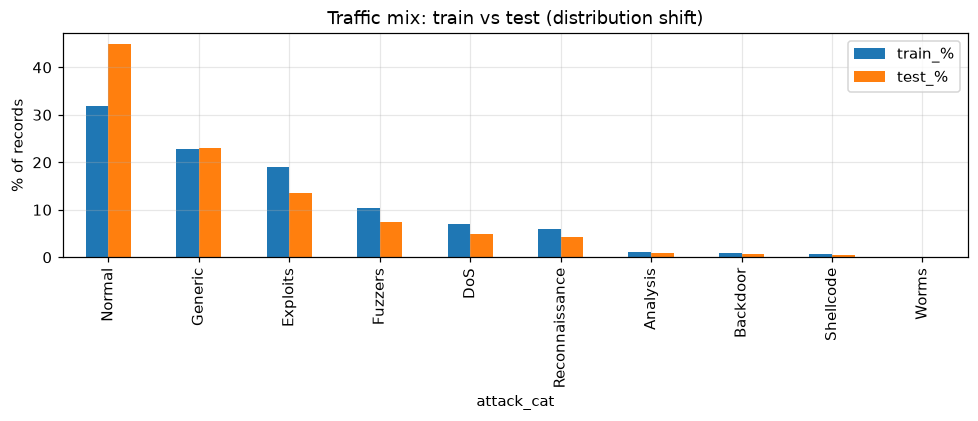

In [4]:
train_raw, test_raw = cfg["loader"]()
if cfg["fe"] is not None:
    train_raw, test_raw = cfg["fe"](train_raw), cfg["fe"](test_raw)

print("train:", train_raw.shape, "| test:", test_raw.shape)
display(train_raw.head(3))

summary = pd.DataFrame({
    "train_rows": [len(train_raw)], "test_rows": [len(test_raw)],
    "train_attack_%": [100 * train_raw[LABEL].mean()], "test_attack_%": [100 * test_raw[LABEL].mean()]})
display(summary)

if CAT_COL:
    comp = pd.concat([train_raw[CAT_COL].value_counts(normalize=True).rename("train_%"),
                      test_raw[CAT_COL].value_counts(normalize=True).rename("test_%")], axis=1) * 100
    display(comp.sort_values("train_%", ascending=False))
    comp.plot.bar(figsize=(9, 4), title="Traffic mix: train vs test (distribution shift)")
    plt.ylabel("% of records"); plt.tight_layout(); show()

## 3. Feature preparation & data splits
* `FEATURES` = every column except IDs, label and attack category (**no label leakage**).
* **Supervised/IsolationForest** use an ordinal-encoded matrix (trees don't need scaling).
* **Autoencoder** uses signed-log + standardisation + one-hot (neural nets need scaled inputs).
* Both preprocessors are **fit on training rows only**.

In [5]:
drop = set(cfg["drop_cols"] + [LABEL] + ([CAT_COL] if CAT_COL else []))
FEATURES = [c for c in train_raw.columns if c not in drop]
CAT_COLS = [c for c in FEATURES if not pd.api.types.is_numeric_dtype(train_raw[c])]   # works for object AND pandas-3 "str" dtype
NUM_COLS = [c for c in FEATURES if c not in CAT_COLS]
print(f"{len(FEATURES)} features  ({len(NUM_COLS)} numeric, {len(CAT_COLS)} categorical: {CAT_COLS})")

# train -> (train, validation). Validation is used for early stopping + threshold tuning.
tr_df, va_df = train_test_split(train_raw, test_size=0.2, stratify=train_raw[LABEL], random_state=RANDOM_STATE)
tr_df, va_df, te_df = (d.reset_index(drop=True) for d in (tr_df, va_df, test_raw))
ytr, yva, yte = (d[LABEL].astype(int).values for d in (tr_df, va_df, te_df))

# --- preprocessor A: ordinal-encoded (LightGBM / RF / IsolationForest) ---
sup_pre = ColumnTransformer(
    [("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), CAT_COLS)],
    remainder="passthrough", verbose_feature_names_out=False)
sup_pre.set_output(transform="pandas")
Xtr = sup_pre.fit_transform(tr_df[FEATURES]);  Xva = sup_pre.transform(va_df[FEATURES]);  Xte = sup_pre.transform(te_df[FEATURES])

# --- preprocessor B: scaled + one-hot (Autoencoder) ---
def signed_log1p(x): return np.sign(x) * np.log1p(np.abs(x))
ae_pre = ColumnTransformer([
    ("num", Pipeline([("log", FunctionTransformer(signed_log1p)), ("sc", StandardScaler())]), NUM_COLS),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_COLS)], sparse_threshold=0)
ae_pre.fit(tr_df.loc[ytr == 0, FEATURES])           # fit on NORMAL rows only
to_ae = lambda df: np.clip(ae_pre.transform(df[FEATURES]), -5, 5)

print("Splits  ->", {"train": len(tr_df), "val": len(va_df), "test": len(te_df)})

49 features  (46 numeric, 3 categorical: ['proto', 'service', 'state'])
Splits  -> {'train': 140272, 'val': 35069, 'test': 82332}


In [6]:
# Sanity check: all model inputs must be numeric before training (fails early with a clear message)
assert not any(Xtr.dtypes.map(lambda t: not pd.api.types.is_numeric_dtype(t))), "Non-numeric column left in Xtr"
assert Xtr.shape[1] == Xva.shape[1] == Xte.shape[1], "Train/val/test feature mismatch"
print("OK: Xtr", Xtr.shape, "| Xva", Xva.shape, "| Xte", Xte.shape, "| attack rate (train):", round(ytr.mean(), 3))

OK: Xtr (140272, 49) | Xva (35069, 49) | Xte (82332, 49) | attack rate (train): 0.681


## 4. Evaluation toolbox
**Realistic prevalence:** UNSW-NB15 has far more attacks than a real network. Instead of throwing data away, every metric can be computed *as if* attacks were only `REAL_PREVALENCE` of events by up-weighting benign rows by a factor `k`. Recall and FPR are unchanged, but **precision, alerts per 1,000 events and cost** become realistic.

Reusable functions used by **both** engines:
* `sweep()` – evaluates *every* candidate threshold (precision, recall, FPR, alert rate, F-beta, SOC cost).
* `pick_operating_points()` – 4 strategies for choosing a threshold.
* `triage_thresholds()` / `tier_report()` – the 3-tier SOC policy.
* `report()` / `fixed_fpr_table()` – metrics at a chosen threshold / at equal false-positive rates.

In [7]:
def reweight_factor(y, prev):
    """k such that benign rows weighted by k make attacks exactly `prev` of all events (None = native mix)."""
    if prev is None:
        return 1.0
    y = np.asarray(y)
    return (y == 1).sum() * (1 - prev) / (prev * (y == 0).sum())

def sample_w(y, prev):
    y = np.asarray(y)
    return np.where(y == 1, 1.0, reweight_factor(y, prev))

def sup_scores(model, X):
    """LightGBM -> raw log-odds (no ties at p=1.0); other models -> predict_proba."""
    if isinstance(model, lgb.LGBMClassifier):
        return model.predict(X, raw_score=True)
    return model.predict_proba(X)[:, 1]

to_prob = lambda z: 1 / (1 + np.exp(-np.clip(z, -50, 50)))        # log-odds -> probability (for display)

def sweep(y, s, beta=F_BETA, n_grid=3000, prev=None, c_fp=None, c_fn=None):
    """Vectorised threshold sweep. Flag = score >= threshold. prev -> metrics at that attack prevalence."""
    c_fp = COST_FP if c_fp is None else c_fp
    c_fn = COST_FN if c_fn is None else c_fn
    y, s = np.asarray(y), np.asarray(s)
    k = reweight_factor(y, prev)
    sp, sn = np.sort(s[y == 1]), np.sort(s[y == 0])
    thr = np.unique(np.concatenate([np.quantile(sn, np.linspace(0, 1, n_grid)),     # fine resolution in the benign tail
                                    np.quantile(sp, np.linspace(0, 1, n_grid))]))
    thr = np.append(thr, np.nextafter(thr.max(), np.inf))                         # 'flag nothing' option
    tp = len(sp) - np.searchsorted(sp, thr, side="left")
    fp = len(sn) - np.searchsorted(sn, thr, side="left")
    fn, tn = len(sp) - tp, len(sn) - fp
    fp_w = fp * k
    prec = np.divide(tp, tp + fp_w, out=np.ones(len(thr)), where=(tp + fp_w) > 0)
    rec = tp / len(sp)
    b2 = beta ** 2
    den = b2 * prec + rec
    fb = np.divide((1 + b2) * prec * rec, den, out=np.zeros(len(thr)), where=den > 0)
    return pd.DataFrame(dict(threshold=thr, precision=prec, recall=rec, fpr=fp / len(sn), f_beta=fb,
                             flagged_rate=(tp + fp_w) / (len(sp) + len(sn) * k),
                             TP=tp, FP=fp, FN=fn, TN=tn, cost=c_fp * fp_w + c_fn * fn))

def pick_operating_points(sw, precision_floor=PRECISION_FLOOR, budget=ALERT_BUDGET):
    """Four ways to choose a threshold -> returns a DataFrame (one row per strategy)."""
    rows = {}
    rows["min_cost (SOC economics)"] = sw.loc[sw["cost"].idxmin()]
    rows[f"max_F{F_BETA:g} (recall-weighted)"] = sw.loc[sw["f_beta"].idxmax()]
    ok = sw[sw["precision"] >= precision_floor]
    rows[f"precision>={precision_floor:.0%} (max recall)"] = ok.loc[ok["recall"].idxmax()] if len(ok) else sw.loc[sw["precision"].idxmax()]
    ok = sw[sw["flagged_rate"] <= budget]
    rows[f"alert budget<={budget:.0%} (max recall)"] = ok.loc[ok["recall"].idxmax()] if len(ok) else sw.iloc[-1]
    out = pd.DataFrame(rows).T.astype(float)
    out["alerts_per_1000"] = 1000 * out["flagged_rate"]
    return out

def report(y, s, thr, name="", prev=None):
    """Metrics at one threshold. prev=None -> native mix; prev=0.02 -> as if attacks were 2% of events."""
    y, s = np.asarray(y), np.asarray(s)
    k = reweight_factor(y, prev)
    pred = s >= thr
    tp, fn = int((pred & (y == 1)).sum()), int((~pred & (y == 1)).sum())
    fp, tn = int((pred & (y == 0)).sum()), int((~pred & (y == 0)).sum())
    fp_w = fp * k
    prec = tp / (tp + fp_w) if (tp + fp_w) > 0 else float("nan")
    rec = tp / max(tp + fn, 1)
    f1 = 2 * prec * rec / (prec + rec) if (tp > 0) else 0.0
    return dict(model=name, threshold=thr, precision=prec, recall=rec, f1=f1, FPR=fp / max(fp + tn, 1),
                TP=tp, FP=fp_w, FN=fn, alerts_per_1000=1000 * (tp + fp_w) / ((y == 1).sum() + (y == 0).sum() * k),
                PR_AUC=average_precision_score(y, s, sample_weight=sample_w(y, prev)), ROC_AUC=roc_auc_score(y, s),
                SOC_cost=COST_FP * fp_w + COST_FN * fn)

def triage_thresholds(y, s, max_missed_frac=MAX_MISSED_FRAC, min_precision=MIN_PRECISION_ESC, prev=REAL_PREVALENCE):
    """t_lo: below it we auto-close (hides <= max_missed_frac of attacks).
       t_hi: from it upward we auto-escalate (precision >= min_precision at the given prevalence)."""
    y, s = np.asarray(y), np.asarray(s)
    order = np.argsort(s); ss = s[order]
    cum = np.cumsum(y[order]) / y.sum()
    i = np.searchsorted(cum, max_missed_frac, side="right")
    t_lo = ss[i - 1] if i > 0 else -np.inf
    sw_ = sweep(y, s, prev=prev)
    ok = sw_[sw_["precision"] >= min_precision]
    t_hi = ok["threshold"].min() if len(ok) else np.inf
    return min(t_lo, t_hi), t_hi

def tier_report(y, s, t_lo, t_hi, prev=None, label=""):
    y, s = np.asarray(y), np.asarray(s)
    w = sample_w(y, prev); N = w.sum()
    closed, esc = s < t_lo, s >= t_hi
    review = ~closed & ~esc
    W = lambda m: float(w[m].sum())
    att, ben = (y == 1), (y == 0)
    out = {
        "% events auto-closed": 100 * W(closed) / N,
        "attacks hidden in auto-closed (count)": int((att & closed).sum()),
        "% events auto-escalated": 100 * W(esc) / N,
        "precision of auto-escalated": W(esc & att) / max(W(esc), 1e-12),
        "% events in analyst queue": 100 * W(review) / N,
        "precision of analyst queue": W(review & att) / max(W(review), 1e-12),
        "alerts reaching humans per 1,000 events": 1000 * (W(esc) + W(review)) / N,
        "% attacks caught (escalated + queue)": 100 * (att & ~closed).sum() / att.sum(),
        "% benign never shown to a human": 100 * W(ben & closed) / max(W(ben), 1e-12) + 0.0}
    return pd.Series(out, name=label)

def plot_pr(ax, y, scores: dict, prev=None):
    w = sample_w(y, prev)
    for name, s in scores.items():
        p, r, _ = precision_recall_curve(y, s, sample_weight=w)
        ax.plot(r, p, label=f"{name} (AP={average_precision_score(y, s, sample_weight=w):.3f})")
    ax.set_xlabel("Recall"); ax.set_ylabel("Precision"); ax.legend(loc="lower left")
    ax.set_title("Precision-Recall" + (f" @ {prev:.1%} attacks" if prev else " (native mix)"))

def fixed_fpr_table(models_va, models_te, fprs=None, prev=REAL_PREVALENCE):
    """Thresholds set so each model has the SAME false-positive rate on benign validation traffic; evaluated on test."""
    fprs = FPR_LEVELS if fprs is None else fprs
    rows = []
    for name in models_va:
        for f in fprs:
            t = float(np.quantile(models_va[name][yva == 0], 1 - f))
            nat, real = report(yte, models_te[name], t, name), report(yte, models_te[name], t, name, prev=prev)
            rows.append(dict(model=name, target_FPR=f, test_FPR=nat["FPR"], recall=nat["recall"],
                             precision_at_prev=real["precision"], alerts_per_1000=real["alerts_per_1000"]))
    return pd.DataFrame(rows)

## 5. Supervised engine — automated alert triage
Goal: **drastically reduce false positives** while keeping missed attacks near zero.

We train **LightGBM** (main model, early-stopped on validation) and a **Random Forest** (baseline).

In [8]:
t0 = time.time()
lgbm = lgb.LGBMClassifier(n_estimators=3000, learning_rate=0.03, num_leaves=63, min_child_samples=30,
                          subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0,
                          random_state=RANDOM_STATE, n_jobs=-1, verbose=-1)
lgbm.fit(Xtr, ytr, eval_set=[(Xva, yva)],
         callbacks=[lgb.early_stopping(100, verbose=False), lgb.log_evaluation(0)])
print(f"LightGBM trained: {lgbm.n_estimators_} trees used, best iteration = {lgbm.best_iteration_}  ({time.time()-t0:.0f}s)")

LightGBM trained: 1734 trees used, best iteration = 1734  (13s)


In [9]:
t0 = time.time()
rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=2, class_weight="balanced_subsample",
                            n_jobs=-1, random_state=RANDOM_STATE).fit(Xtr, ytr)
print(f"RandomForest trained ({time.time()-t0:.0f}s)")

RandomForest trained (15s)


In [10]:
p_va = {"LightGBM": sup_scores(lgbm, Xva), "RandomForest": sup_scores(rf, Xva)}    # LightGBM = log-odds
wva = sample_w(yva, REAL_PREVALENCE)
for k_, v_ in p_va.items():
    print(f"{k_:13s} AP (native mix) = {average_precision_score(yva, v_):.4f} | AP @ {REAL_PREVALENCE:.0%} attacks = {average_precision_score(yva, v_, sample_weight=wva):.4f}")

LightGBM      AP (native mix) = 0.9976 | AP @ 2% attacks = 0.9176
RandomForest  AP (native mix) = 0.9972 | AP @ 2% attacks = 0.9045


### 5.1 Tune the supervised decision policy on **validation** (at a realistic attack rate)
First the classic single threshold, then the 3-tier SOC policy. LightGBM thresholds are in **log-odds**; the printout also shows the equivalent probability.

In [11]:
sw_lgb = sweep(yva, p_va["LightGBM"], prev=REAL_PREVALENCE)
ops_lgb = pick_operating_points(sw_lgb)
display(ops_lgb[["threshold", "precision", "recall", "fpr", "alerts_per_1000", "FP", "FN", "cost"]])

T_SUP = float(ops_lgb.iloc[0]["threshold"])           # min-cost threshold = default SOC choice
T_LO, T_HI = triage_thresholds(yva, p_va["LightGBM"], prev=REAL_PREVALENCE)
print(f"\nSupervised single threshold (min-cost): log-odds {T_SUP:.3f}  (p = {to_prob(T_SUP):.4f})")
print(f"3-tier policy: auto-close if p < {to_prob(T_LO):.4f} | analyst review if {to_prob(T_LO):.4f} <= p < {to_prob(T_HI):.4f} | auto-escalate if p >= {to_prob(T_HI):.4f}")
display(pd.concat([tier_report(yva, p_va["LightGBM"], T_LO, T_HI, prev=None, label="validation (native mix)"),
                   tier_report(yva, p_va["LightGBM"], T_LO, T_HI, prev=REAL_PREVALENCE, label=f"validation @ {REAL_PREVALENCE:.0%} attacks")], axis=1))

,threshold,precision,recall,fpr,alerts_per_1000,FP,FN,cost
min_cost (SOC economics),0.5358,0.2936,0.9656,0.0474,65.7754,531.0000,820.0000,"96,450.6706"
max_F2 (recall-weighted),3.6515,0.8519,0.8556,0.0030,20.0867,34.0000,"3,447.0000","175,900.5138"
precision>=90% (max recall),4.0406,0.9018,0.8433,0.0019,18.7029,21.0000,"3,741.0000","189,242.9644"
alert budget<=5% (max recall),1.0728,0.3797,0.9480,0.0316,49.9343,354.0000,"1,242.0000","99,067.1137"



Supervised single threshold (min-cost): log-odds 0.536  (p = 0.6308)
3-tier policy: auto-close if p < 0.2191 | analyst review if 0.2191 <= p < 0.9924 | auto-escalate if p >= 0.9924


,validation (native mix),validation @ 2% attacks
% events auto-closed,28.1360,85.3050
attacks hidden in auto-closed (count),119.0000,119.0000
% events auto-escalated,55.6275,1.7126
precision of auto-escalated,0.9995,0.9540
% events in analyst queue,16.2366,12.9824
precision of analyst queue,0.7466,0.0274
"alerts reaching humans per 1,000 events",718.6404,146.9503
% attacks caught (escalated + queue),99.5014,99.5014
% benign never shown to a human,87.0357,87.0357


## 6. Unsupervised engine — behavioural anomaly detection
Both models are trained **only on normal behaviour** (no attack labels), so they model "what normal looks like" and flag deviations.
This is how you catch **novel / polymorphic** activity (UNSW) or **unusual user behaviour** (CERT insider threats).

* **Isolation Forest** — attacks are "easy to isolate" → short tree paths.
* **Autoencoder** — compresses normal data through a bottleneck; anomalies **reconstruct badly** (high error).
  Implemented with scikit-learn's `MLPRegressor` (input → input) so no deep-learning framework is required.

IsolationForest trained (1s)
Autoencoder trained on 44,800 normal rows, 70 inputs -> bottleneck 16  (29s)
{'IsolationForest': 'AP=0.8941 | ROC-AUC=0.8504', 'Autoencoder': 'AP=0.9704 | ROC-AUC=0.9407'}



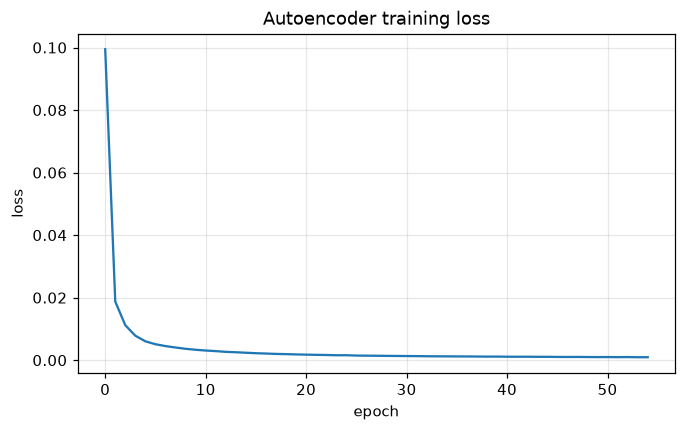

In [12]:
normal_idx = np.where(ytr == 0)[0]

# ---------------- Isolation Forest ----------------
t0 = time.time()
iso = IsolationForest(n_estimators=400, max_samples=512, contamination="auto",
                      random_state=RANDOM_STATE, n_jobs=-1).fit(Xtr.iloc[normal_idx])
iso_score = lambda X: -iso.score_samples(X)                  # higher = more anomalous
print(f"IsolationForest trained ({time.time()-t0:.0f}s)")

# ---------------- Autoencoder ----------------
t0 = time.time()
rng = np.random.RandomState(RANDOM_STATE)
ae_idx = rng.choice(normal_idx, size=min(AE_MAX_ROWS, len(normal_idx)), replace=False)
Z = to_ae(tr_df.iloc[ae_idx])
d = Z.shape[1]
ae = MLPRegressor(hidden_layer_sizes=(128, 64, 16, 64, 128), activation="relu", alpha=1e-5,
                  learning_rate_init=1e-3, batch_size=256, max_iter=60, early_stopping=True,
                  validation_fraction=0.1, n_iter_no_change=6, random_state=RANDOM_STATE)
ae.fit(Z, Z)                                                  # reconstruct the input
ae_score = lambda df: ((to_ae(df) - ae.predict(to_ae(df))) ** 2).mean(axis=1)   # reconstruction MSE
print(f"Autoencoder trained on {len(Z):,} normal rows, {d} inputs -> bottleneck 16  ({time.time()-t0:.0f}s)")

s_va = {"IsolationForest": iso_score(Xva), "Autoencoder": ae_score(va_df)}
print({k: f"AP={average_precision_score(yva, v):.4f} | ROC-AUC={roc_auc_score(yva, v):.4f}" for k, v in s_va.items()})

plt.figure(figsize=(7, 4))
plt.plot(ae.loss_curve_); plt.title("Autoencoder training loss"); plt.xlabel("epoch"); plt.ylabel("loss"); show()

## 7. 🎯 Optimization task — anomaly-threshold tuning for a high-stakes SOC
An anomaly score is useless until it becomes a **yes/no alert**. The threshold controls the trade-off:

* **Too low** → alert fatigue (analysts drown in false positives, real attacks get ignored).
* **Too high** → missed attacks (breach).

We compare four strategies **on validation data only**, with benign events re-weighted to a realistic attack rate (`REAL_PREVALENCE`):

| Strategy | Question it answers |
|---|---|
| `min_cost` | Which threshold minimises `COST_FP·FP + COST_FN·FN`? |
| `max_F2` | Best balance when recall matters 2× more than precision |
| `precision floor` | Highest recall while keeping analysts' time well spent (≥ 90 % true alerts) |
| `alert budget` | Highest recall given a fixed daily capacity (e.g., 5 % of events) |

> If `min_cost` picks *"flag nothing"* (recall 0) for a detector, that is a real finding: at this cost ratio and attack rate the detector is **not good enough to run alone**.


=== IsolationForest: operating points (validation, 2% attacks) ===


,threshold,precision,recall,fpr,alerts_per_1000,FP,FN,cost
min_cost (SOC economics),0.4031,0.0663,0.8599,0.2471,259.3114,"2,767.0000","3,343.0000","456,099.1631"
max_F2 (recall-weighted),0.4764,0.1096,0.4192,0.0695,76.4583,778.0000,"13,864.0000","774,444.1088"
precision>=90% (max recall),0.6464,1.0000,0.0013,0.0000,0.0268,0.0000,"23,837.0000","1,191,850.0000"
alert budget<=5% (max recall),0.5092,0.1204,0.3005,0.0448,49.9353,502.0000,"16,696.0000","887,222.2913"



=== Autoencoder: operating points (validation, 2% attacks) ===


,threshold,precision,recall,fpr,alerts_per_1000,FP,FN,cost
min_cost (SOC economics),0.0043,0.1779,0.8274,0.0780,93.0237,874.0000,"4,119.0000","297,219.0887"
max_F2 (recall-weighted),0.0180,0.4946,0.7151,0.0149,28.9139,167.0000,"6,801.0000","357,489.2881"
precision>=90% (max recall),0.3528,1.0000,0.0157,0.0000,0.3142,0.0000,"23,494.0000","1,174,700.0000"
alert budget<=5% (max recall),0.0086,0.3042,0.7592,0.0354,49.9220,397.0000,"5,747.0000","328,807.4694"



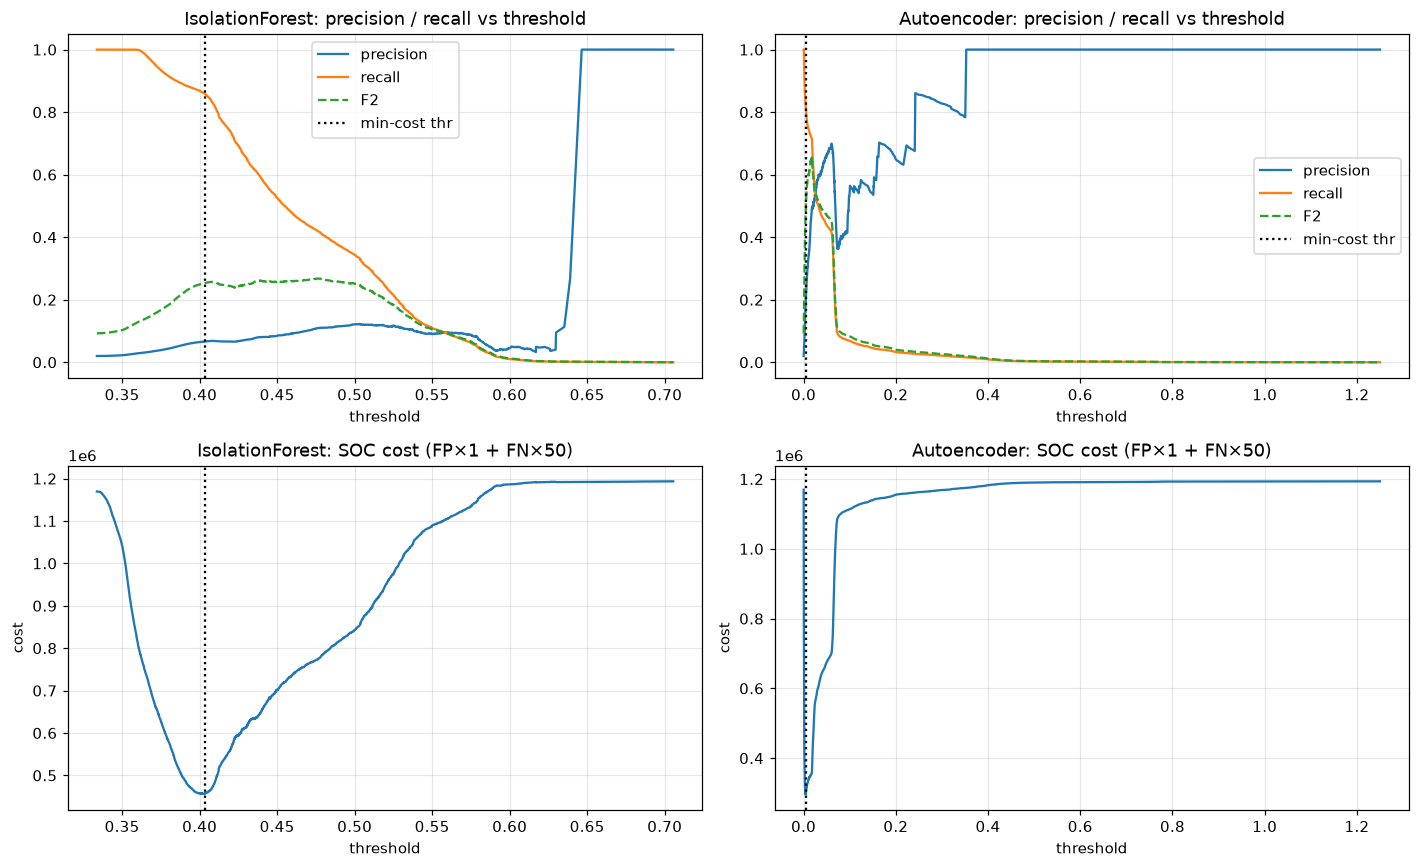

In [13]:
sw = {name: sweep(yva, s, prev=REAL_PREVALENCE) for name, s in s_va.items()}
ops = {name: pick_operating_points(sw[name]) for name in sw}
for name in ops:
    print(f"\n=== {name}: operating points (validation, {REAL_PREVALENCE:.0%} attacks) ===")
    display(ops[name][["threshold", "precision", "recall", "fpr", "alerts_per_1000", "FP", "FN", "cost"]])

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for j, name in enumerate(sw):
    s = sw[name]
    ax = axes[0, j]
    ax.plot(s["threshold"], s["precision"], label="precision"); ax.plot(s["threshold"], s["recall"], label="recall")
    ax.plot(s["threshold"], s["f_beta"], label=f"F{F_BETA:g}", ls="--")
    ax.axvline(ops[name].iloc[0]["threshold"], color="k", ls=":", label="min-cost thr")
    ax.set_title(f"{name}: precision / recall vs threshold"); ax.set_xlabel("threshold"); ax.legend()
    ax = axes[1, j]
    ax.plot(s["threshold"], s["cost"]); ax.axvline(ops[name].iloc[0]["threshold"], color="k", ls=":")
    ax.set_title(f"{name}: SOC cost (FP×{COST_FP} + FN×{COST_FN})"); ax.set_xlabel("threshold"); ax.set_ylabel("cost")
plt.tight_layout(); show()

### 7.1 Equal-false-positive-rate view (and the label-free fallback)
In production you often have **no labels**. A defensible alternative is to set the threshold at a high percentile of the **benign-only** score distribution: *"I accept at most X false alerts per 1,000 benign events"*. It is also the fairest way to compare detectors: **same false alarms → who catches more?**

In [14]:
val_scores = {**p_va, **s_va}
rows = []
for name, s in val_scores.items():
    for f in FPR_LEVELS:
        t = float(np.quantile(s[yva == 0], 1 - f))
        r = report(yva, s, t, name, prev=REAL_PREVALENCE)
        rows.append(dict(model=name, target_FPR=f, recall=r["recall"], precision_at_prev=r["precision"], alerts_per_1000=r["alerts_per_1000"]))
fx_val = pd.DataFrame(rows)
print("Validation recall at equal false-positive rate:")
display(fx_val.pivot(index="model", columns="target_FPR", values="recall"))
print(f"Precision at {REAL_PREVALENCE:.0%} attack prevalence:")
display(fx_val.pivot(index="model", columns="target_FPR", values="precision_at_prev"))

Validation recall at equal false-positive rate:


target_FPR,0.0010,0.0100,0.0500
model,,,
Autoencoder,0.0635,0.5479,0.7855
IsolationForest,0.0020,0.0201,0.3399
LightGBM,0.8245,0.8984,0.9671
RandomForest,0.7973,0.8907,0.9612


Precision at 2% attack prevalence:


target_FPR,0.0010,0.0100,0.0500
model,,,
Autoencoder,0.5475,0.5279,0.2424
IsolationForest,0.0362,0.0394,0.1218
LightGBM,0.9401,0.6471,0.2830
RandomForest,0.9382,0.6451,0.2818


### 7.2 How sensitive is the optimal threshold to cost and attack rate?
The "best" threshold is **not universal**. It moves with how expensive a miss is (`COST_FN`) and how rare attacks are (prevalence). Read across a row to see the effect for LightGBM.

In [15]:
rows = []
for cfn in [5, 20, 50, 200, 1000]:
    for prev in [0.005, 0.02, 0.10]:
        r = sweep(yva, p_va["LightGBM"], prev=prev, c_fn=cfn).pipe(lambda d: d.loc[d["cost"].idxmin()])
        rows.append(dict(COST_FN=cfn, prevalence=prev, threshold_p=float(to_prob(r["threshold"])),
                         recall=r["recall"], FPR=r["fpr"], alerts_per_1000=1000 * r["flagged_rate"]))
sens = pd.DataFrame(rows)
for col in ["recall", "FPR", "alerts_per_1000"]:
    print(f"\n{col} at the min-cost threshold:")
    display(sens.pivot(index="COST_FN", columns="prevalence", values=col))


recall at the min-cost threshold:


prevalence,0.0050,0.0200,0.1000
COST_FN,,,
5,0.8169,0.8556,0.9300
20,0.8556,0.9256,0.9805
50,0.8979,0.9656,0.9952
200,0.9656,0.9873,0.9988
1000,0.9939,0.9988,1.0000



FPR at the min-cost threshold:


prevalence,0.0050,0.0200,0.1000
COST_FN,,,
5,0.0008,0.0030,0.0202
20,0.0030,0.0180,0.0741
50,0.0098,0.0474,0.1301
200,0.0474,0.0942,0.1707
1000,0.1234,0.1707,0.2018



alerts_per_1000 at the min-cost threshold:


prevalence,0.0050,0.0200,0.1000
COST_FN,,,
5,4.8841,20.0867,111.1558
20,7.2985,36.1877,164.7441
50,14.2620,65.7754,216.5986
200,52.0019,112.0586,253.5256
1000,127.7455,187.2765,281.6071


## 8. Hybrid risk score — combine both engines
The supervised model is great at **known** attacks; the anomaly detectors may help with **unknown** ones.
Each score is converted to a **z-score relative to benign validation traffic** (robust median / IQR, autoencoder error on a log scale), so the three engines are on the same scale without creating ties:

`risk = w · z_supervised  +  (1 − w) · max(z_IsolationForest, z_Autoencoder)`

`w` is picked on validation by PR-AUC *at the realistic attack rate*. Among blends within 0.002 of the best PR-AUC we take the **smallest w** (most anomaly-aware, usually more robust to new attacks). If the chosen `w` is 1.0, the anomaly detectors simply add nothing on this data — and the notebook says so.

w (weight on supervised),0.0000,0.1000,0.2000,0.3000,0.4000,0.5000,0.6000,0.7000,0.8000,0.9000,1.0000
PR-AUC @ 2% attacks,0.1204,0.2007,0.4232,0.6677,0.7836,0.8450,0.8801,0.9012,0.9115,0.9161,0.9176



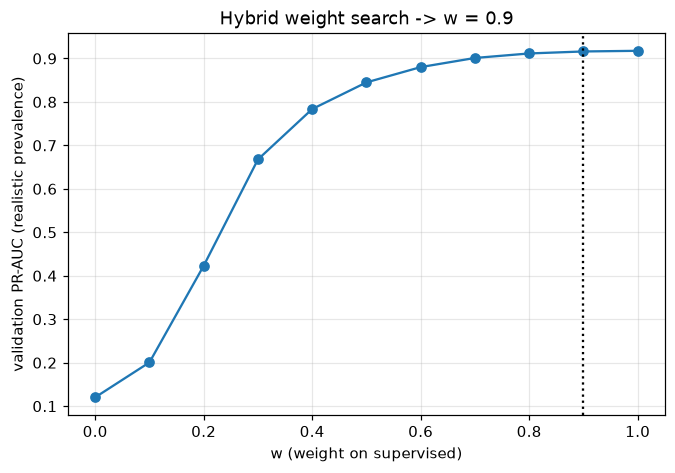

Chosen w = 0.9  |  supervised-only AP = 0.9176  |  hybrid AP = 0.9161
-> anomaly engines contribute to the blend.


,threshold,precision,recall,fpr,alerts_per_1000,FP,FN,cost
min_cost (SOC economics),5.0108,0.3058,0.9616,0.0446,62.8950,499.0000,916.0000,"97,909.0106"
max_F2 (recall-weighted),6.4982,0.8780,0.8499,0.0024,19.3611,27.0000,"3,582.0000","181,919.5256"
precision>=90% (max recall),6.6407,0.9014,0.8399,0.0019,18.6359,21.0000,"3,821.0000","193,242.9644"
alert budget<=5% (max recall),5.2302,0.3784,0.9455,0.0317,49.9715,355.0000,"1,302.0000","102,171.5406"


In [16]:
def make_norm(ref, log=False):
    """Robust z-score relative to benign reference scores."""
    f = (lambda a: np.log(np.asarray(a) + 1e-12)) if log else (lambda a: np.asarray(a, dtype=float))
    r = f(ref); med = np.median(r); sd = (np.quantile(r, .75) - np.quantile(r, .25)) / 1.349 + 1e-9
    return lambda s: (f(s) - med) / sd

norm_sup = make_norm(p_va["LightGBM"][yva == 0])
norm_if  = make_norm(s_va["IsolationForest"][yva == 0])
norm_ae  = make_norm(s_va["Autoencoder"][yva == 0], log=True)

def hybrid(w, sup, s_if, s_ae):
    return w * norm_sup(sup) + (1 - w) * np.maximum(norm_if(s_if), norm_ae(s_ae))

grid = np.round(np.arange(0.0, 1.01, 0.1), 2)
ap_w = np.array([average_precision_score(yva, hybrid(w, p_va["LightGBM"], s_va["IsolationForest"], s_va["Autoencoder"]),
                                         sample_weight=wva) for w in grid])
near_best = np.where(ap_w >= ap_w.max() - 0.002)[0]
W = float(grid[near_best.min()])
display(pd.DataFrame({"w (weight on supervised)": grid, f"PR-AUC @ {REAL_PREVALENCE:.0%} attacks": ap_w}).set_index("w (weight on supervised)").T)
plt.plot(grid, ap_w, marker="o"); plt.axvline(W, color="k", ls=":")
plt.xlabel("w (weight on supervised)"); plt.ylabel("validation PR-AUC (realistic prevalence)")
plt.title(f"Hybrid weight search -> w = {W}"); show()
print(f"Chosen w = {W}  |  supervised-only AP = {ap_w[-1]:.4f}  |  hybrid AP = {ap_w[int(np.where(grid == W)[0][0])]:.4f}")
print("-> anomaly engines add NOTHING on validation (w=1)." if W == 1.0 else "-> anomaly engines contribute to the blend.")

hy_va = hybrid(W, p_va["LightGBM"], s_va["IsolationForest"], s_va["Autoencoder"])
ops_hy = pick_operating_points(sweep(yva, hy_va, prev=REAL_PREVALENCE))
display(ops_hy[["threshold", "precision", "recall", "fpr", "alerts_per_1000", "FP", "FN", "cost"]])

## 9. 🧪 Final evaluation on the held-out **testing-set**
Thresholds below were all chosen on validation at the realistic attack rate. Nothing is re-tuned on test.
Each model is reported twice: **native mix** (what UNSW-NB15 actually contains) and **realistic prevalence** (what a SOC would experience). Note LightGBM thresholds are in log-odds.

=== TEST - native UNSW mix (FP = false alerts) ===


,threshold,precision,recall,f1,FPR,FP,FN,alerts_per_1000,PR_AUC,ROC_AUC,SOC_cost
model,,,,,,,,,,,
LightGBM,0.5358,0.8528,0.9721,0.9086,0.2056,"7,606.0000",1265,627.6175,0.9876,0.9831,"70,856.0000"
RandomForest,0.6402,0.8913,0.9601,0.9244,0.1435,"5,309.0000",1808,593.1230,0.9877,0.9838,"95,709.0000"
IsolationForest,0.4031,0.7417,0.8487,0.7916,0.3621,"13,396.0000",6859,629.9981,0.7921,0.7874,"356,346.0000"
Autoencoder,0.0043,0.8652,0.8905,0.8777,0.1700,"6,291.0000",4962,566.7420,0.9388,0.9336,"254,391.0000"
Hybrid,5.0108,0.8598,0.9730,0.9129,0.1945,"7,195.0000",1222,623.1477,0.9882,0.9840,"68,295.0000"
LightGBM @ default p=0.5,0.0000,0.8212,0.9826,0.8947,0.2621,"9,697.0000",788,658.8082,0.9876,0.9831,"49,097.0000"


=== TEST - realistic prevalence (2% attacks; FP scaled) ===


,threshold,precision,recall,f1,FPR,FP,FN,alerts_per_1000,PR_AUC,ROC_AUC,SOC_cost
model,,,,,,,,,,,
LightGBM,0.5358,0.0880,0.9721,0.1614,0.2056,"456,620.6597",1265,220.8981,0.8774,0.9831,"519,870.6597"
RandomForest,0.6402,0.1202,0.9601,0.2136,0.1435,"318,721.9409",1808,159.8191,0.8457,0.9838,"409,121.9409"
IsolationForest,0.4031,0.0457,0.8487,0.0866,0.3621,"804,219.0845",6859,371.7869,0.0784,0.7874,"1,147,169.0845"
Autoencoder,0.0043,0.0966,0.8905,0.1742,0.1700,"377,675.5943",4962,184.4373,0.3016,0.9336,"625,775.5943"
Hybrid,5.0108,0.0927,0.9730,0.1692,0.1945,"431,946.5746",1222,210.0311,0.8770,0.9840,"493,046.5746"
LightGBM @ default p=0.5,0.0000,0.0711,0.9826,0.1326,0.2621,"582,152.3188",788,276.4918,0.8774,0.9831,"621,552.3188"


,benign flagged (%),FP reduction vs alert-on-everything (%),attacks missed,alerts / 1000 events @ 2% attacks
model,,,,
LightGBM,20.5568,79.4432,1265,220.8981
RandomForest,14.3486,85.6514,1808,159.8191
IsolationForest,36.2054,63.7946,6859,371.7869
Autoencoder,17.0027,82.9973,4962,184.4373
Hybrid,19.4459,80.5541,1222,210.0311
LightGBM @ default p=0.5,26.2081,73.7919,788,276.4918



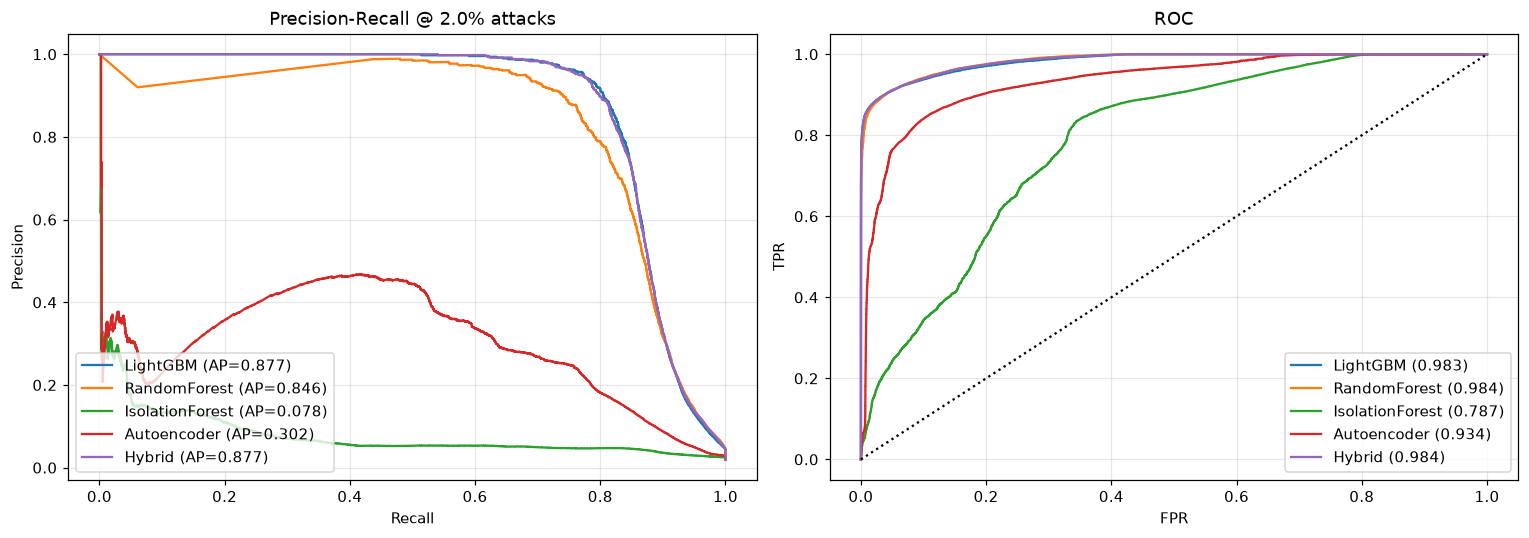

In [17]:
# ---- score the test set with every model ----
p_te = {"LightGBM": sup_scores(lgbm, Xte), "RandomForest": sup_scores(rf, Xte)}
s_te = {"IsolationForest": iso_score(Xte), "Autoencoder": ae_score(te_df)}
hy_te = hybrid(W, p_te["LightGBM"], s_te["IsolationForest"], s_te["Autoencoder"])
all_te = {**p_te, **s_te, "Hybrid": hy_te}
all_va = {**p_va, **s_va, "Hybrid": hy_va}

# ---- thresholds chosen on validation (min-cost strategy, realistic prevalence) ----
thr = {"LightGBM": T_SUP,
       "RandomForest": float(pick_operating_points(sweep(yva, p_va["RandomForest"], prev=REAL_PREVALENCE)).iloc[0]["threshold"]),
       "IsolationForest": float(ops["IsolationForest"].iloc[0]["threshold"]),
       "Autoencoder": float(ops["Autoencoder"].iloc[0]["threshold"]),
       "Hybrid": float(ops_hy.iloc[0]["threshold"])}

def build_results(prev):
    rows = [report(yte, all_te[m], thr[m], m, prev=prev) for m in all_te]
    rows.append(report(yte, p_te["LightGBM"], 0.0, "LightGBM @ default p=0.5", prev=prev))     # log-odds 0 == p 0.5
    return pd.DataFrame(rows).set_index("model")

cols = ["threshold", "precision", "recall", "f1", "FPR", "FP", "FN", "alerts_per_1000", "PR_AUC", "ROC_AUC", "SOC_cost"]
res_native, res_real = build_results(None), build_results(REAL_PREVALENCE)
print("=== TEST - native UNSW mix (FP = false alerts) ===");                         display(res_native[cols])
print(f"=== TEST - realistic prevalence ({REAL_PREVALENCE:.0%} attacks; FP scaled) ==="); display(res_real[cols])

# ---- False-positive burden ----
fp_tbl = pd.DataFrame({"benign flagged (%)": 100 * res_native["FPR"],
                       "FP reduction vs alert-on-everything (%)": 100 * (1 - res_native["FPR"]),
                       "attacks missed": res_native["FN"],
                       f"alerts / 1000 events @ {REAL_PREVALENCE:.0%} attacks": res_real["alerts_per_1000"]})
display(fp_tbl)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
plot_pr(ax[0], yte, all_te, prev=REAL_PREVALENCE)
for n, s in all_te.items():
    f, t, _ = roc_curve(yte, s); ax[1].plot(f, t, label=f"{n} ({roc_auc_score(yte, s):.3f})")
ax[1].plot([0, 1], [0, 1], "k:"); ax[1].set_xlabel("FPR"); ax[1].set_ylabel("TPR"); ax[1].legend(); ax[1].set_title("ROC")
plt.tight_layout(); show()

### 9.1 3-tier SOC triage on the test set
How much analyst workload does the supervised engine remove, and how many attacks slip through? Shown for the native mix and for a realistic attack rate. Compare *precision of auto-escalated* here with validation: a drop means the attack mix shifted (thresholds drift).

,test (native mix),test @ 2% attacks
% events auto-closed,28.2588,61.1130
attacks hidden in auto-closed (count),196.0000,196.0000
% events auto-escalated,46.2372,2.0988
precision of auto-escalated,0.9958,0.7968
% events in analyst queue,25.5041,36.7882
precision of analyst queue,0.3443,0.0087
"alerts reaching humans per 1,000 events",717.4124,388.8703
% attacks caught (escalated + queue),99.5676,99.5676
% benign never shown to a human,62.3514,62.3514



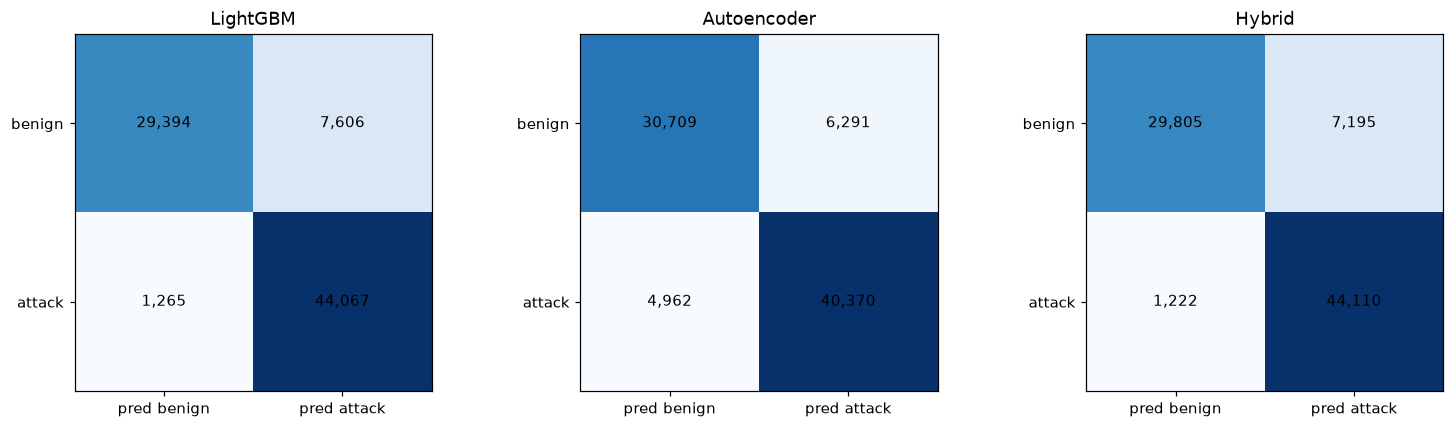

In [18]:
display(pd.concat([tier_report(yte, p_te["LightGBM"], T_LO, T_HI, prev=None, label="test (native mix)"),
                   tier_report(yte, p_te["LightGBM"], T_LO, T_HI, prev=REAL_PREVALENCE, label=f"test @ {REAL_PREVALENCE:.0%} attacks")], axis=1))

# confusion matrices at the chosen thresholds (native mix)
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, m in zip(axes, ["LightGBM", "Autoencoder", "Hybrid"]):
    cm = confusion_matrix(yte, (all_te[m] >= thr[m]).astype(int), labels=[0, 1])
    ax.imshow(cm, cmap="Blues")
    for (i, j), v in np.ndenumerate(cm): ax.text(j, i, f"{v:,}", ha="center", va="center", color="black")
    ax.set_xticks([0, 1], ["pred benign", "pred attack"]); ax.set_yticks([0, 1], ["benign", "attack"]); ax.set_title(m); ax.grid(False)
plt.tight_layout(); show()

### 9.2 ⚖️ Fair comparison: every model at the **same false-positive rate**
Thresholds are set on benign **validation** traffic so each model produces the same share of false alarms; we then measure recall on the test set. `test_FPR` shows how far real test traffic drifts from the target.

TEST recall at equal false-positive rate:


target_FPR,0.0010,0.0100,0.0500
model,,,
Autoencoder,0.0552,0.6516,0.8575
Hybrid,0.8463,0.9179,0.9762
IsolationForest,0.0030,0.0536,0.2748
LightGBM,0.8436,0.9195,0.9734
RandomForest,0.7643,0.9004,0.9715


TEST false-positive rate actually obtained (drift check):


target_FPR,0.0010,0.0100,0.0500
model,,,
Autoencoder,0.0026,0.0334,0.1179
Hybrid,0.0059,0.0601,0.2071
IsolationForest,0.0001,0.0062,0.0664
LightGBM,0.0052,0.0619,0.2124
RandomForest,0.0025,0.0400,0.1838


Precision at 2% attack prevalence:


target_FPR,0.0010,0.0100,0.0500
model,,,
Autoencoder,0.3027,0.2849,0.1293
Hybrid,0.7448,0.2378,0.0878
IsolationForest,0.3582,0.1509,0.0779
LightGBM,0.7675,0.2327,0.0855
RandomForest,0.8638,0.3149,0.0974



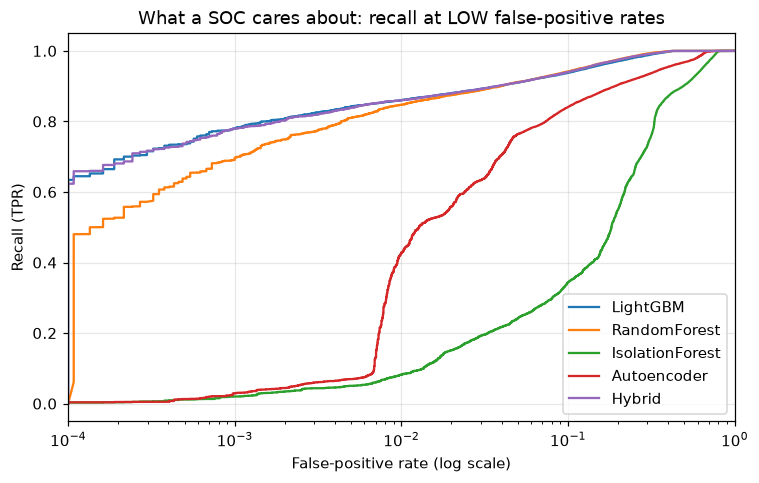

In [19]:
fx = fixed_fpr_table(all_va, all_te)
print("TEST recall at equal false-positive rate:");                      display(fx.pivot(index="model", columns="target_FPR", values="recall"))
print("TEST false-positive rate actually obtained (drift check):");      display(fx.pivot(index="model", columns="target_FPR", values="test_FPR"))
print(f"Precision at {REAL_PREVALENCE:.0%} attack prevalence:");           display(fx.pivot(index="model", columns="target_FPR", values="precision_at_prev"))

fig, ax = plt.subplots(figsize=(7, 4.5))
for n, s in all_te.items():
    f, t, _ = roc_curve(yte, s); ax.plot(np.clip(f, 1e-4, 1), t, label=n)
ax.set_xscale("log"); ax.set_xlim(1e-4, 1); ax.set_xlabel("False-positive rate (log scale)"); ax.set_ylabel("Recall (TPR)")
ax.set_title("What a SOC cares about: recall at LOW false-positive rates"); ax.legend(); plt.tight_layout(); show()

## 10. Which attack families are caught? (per-category recall)
Compared at an **equal 1 % false-positive rate** (threshold from benign validation traffic), so the numbers can't be inflated by flagging everything. Only available when the dataset has a category column (UNSW-NB15: `attack_cat`).

,LightGBM,RandomForest,IsolationForest,Autoencoder,Hybrid,n_test
attack_cat,,,,,,
Generic,0.9984,0.9945,0.1164,0.9836,0.9979,18871
Exploits,0.9714,0.9572,0.0141,0.5991,0.9693,11132
Fuzzers,0.4914,0.4134,0.0028,0.2237,0.4898,6062
DoS,0.9836,0.9645,0.0149,0.4351,0.9809,4089
Reconnaissance,0.9866,0.9691,0.0000,0.0758,0.9828,3496
Analysis,0.9188,0.9114,0.0000,0.6750,0.9202,677
Backdoor,0.9949,0.9846,0.0000,0.7513,0.9914,583
Shellcode,0.8836,0.8519,0.0000,0.0106,0.8624,378
Worms,1.0000,0.9545,0.0227,0.1818,1.0000,44



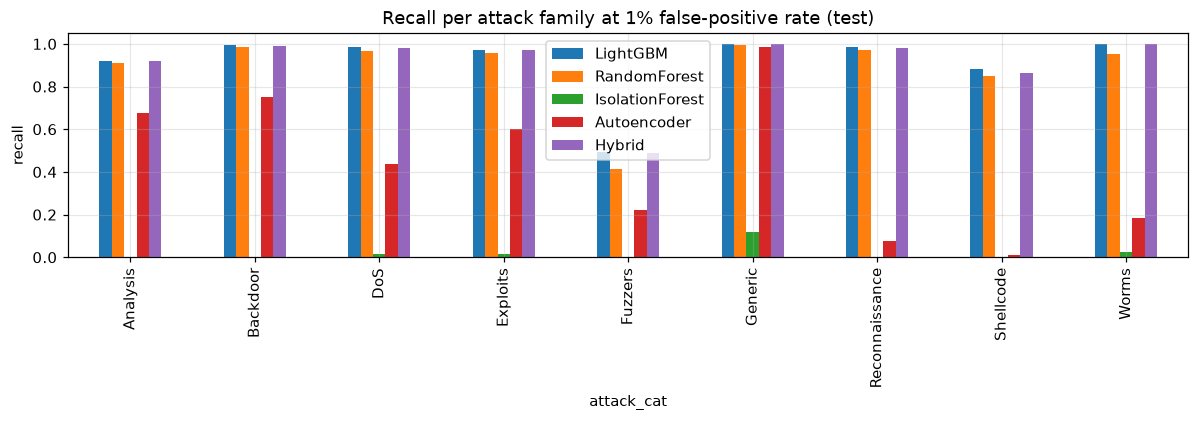

In [20]:
FPR_CAT = 0.01
thr_cat = {m: float(np.quantile(all_va[m][yva == 0], 1 - FPR_CAT)) for m in all_te}

def cat_recall(df, scores, t):
    a = df[df[LABEL] == 1]
    hit = (np.asarray(scores)[a.index] >= t).astype(int)
    return pd.Series(hit, index=a.index).groupby(a[CAT_COL]).mean()

if CAT_COL:
    tbl = pd.DataFrame({m: cat_recall(te_df, all_te[m], thr_cat[m]) for m in all_te})
    tbl["n_test"] = te_df[te_df[LABEL] == 1][CAT_COL].value_counts()
    display(tbl.sort_values("n_test", ascending=False))
    tbl.drop(columns="n_test").plot.bar(figsize=(11, 4), title=f"Recall per attack family at {FPR_CAT:.0%} false-positive rate (test)")
    plt.ylabel("recall"); plt.tight_layout(); show()
else:
    print("No category column for this dataset - skipping.")

## 11. 🧬 Zero-day simulation
Remove entire attack families from **training**, then check who still catches them in the test set — again at **equal false-positive rates** (1 % and 5 %).
The supervised model has *never seen* these families; the unsupervised engines never see **any** attack. A row `(seen families)` is included as the reference: the gap between it and the blind rows is the cost of a never-before-seen attack.

In [21]:
HOLDOUT = ["Backdoor", "Shellcode", "Worms", "Analysis"]      # <-- edit: families to hide from the supervised model

if CAT_COL:
    keep_tr = ~tr_df[CAT_COL].isin(HOLDOUT).values
    lgb_zd = lgb.LGBMClassifier(n_estimators=400, learning_rate=0.05, num_leaves=31, random_state=RANDOM_STATE,
                                n_jobs=-1, verbose=-1).fit(Xtr[keep_tr], ytr[keep_tr])
    zd_va, zd_te = lgb_zd.predict(Xva, raw_score=True), lgb_zd.predict(Xte, raw_score=True)

    models_zd = {"LightGBM (blind to these)": (zd_va, zd_te),
                 "IsolationForest": (s_va["IsolationForest"], s_te["IsolationForest"]),
                 "Autoencoder": (s_va["Autoencoder"], s_te["Autoencoder"])}
    is_hold = te_df[CAT_COL].isin(HOLDOUT).values
    att = (yte == 1)
    for f in [0.01, 0.05]:
        rows = {}
        for n, (sv, st) in models_zd.items():
            t = float(np.quantile(sv[yva == 0], 1 - f))               # threshold from BENIGN validation only
            hit = st >= t
            r = {fam: hit[(te_df[CAT_COL] == fam).values].mean() for fam in HOLDOUT}
            r["(unseen families, all)"] = hit[att & is_hold].mean()
            r["(seen families, all)"] = hit[att & ~is_hold].mean()
            rows[n] = r
        print(f"\nTest recall at {f:.0%} false-positive rate:")
        display(pd.DataFrame(rows))
    print("\nRead it as: if the supervised model's recall on unseen families collapses while the anomaly engines keep some, "
          "that is the argument for running both. If the anomaly engines are also low, they are not yet a safety net on this data.")
else:
    print("No category column - skipping zero-day simulation (for CERT, hold out whole insider scenarios instead).")


Test recall at 1% false-positive rate:


,LightGBM (blind to these),IsolationForest,Autoencoder
Backdoor,0.9897,0.0000,0.7513
Shellcode,0.8201,0.0000,0.0106
Worms,1.0000,0.0227,0.1818
Analysis,0.9158,0.0000,0.6750
"(unseen families, all)",0.9221,0.0006,0.5392
"(seen families, all)",0.9092,0.0557,0.6559



Test recall at 5% false-positive rate:


,LightGBM (blind to these),IsolationForest,Autoencoder
Backdoor,0.9983,0.0772,0.9537
Shellcode,0.9894,0.0185,0.1032
Worms,1.0000,0.2045,0.6591
Analysis,0.9424,0.0517,1.0000
"(unseen families, all)",0.9738,0.0571,0.7735
"(seen families, all)",0.9721,0.2832,0.8607



Read it as: if the supervised model's recall on unseen families collapses while the anomaly engines keep some, that is the argument for running both. If the anomaly engines are also low, they are not yet a safety net on this data.


## 12. 🔍 Explainability — *why* did this alert fire?
Analysts trust (and act on) alerts they can understand. LightGBM can return per-feature contributions (SHAP-style) with no extra library.


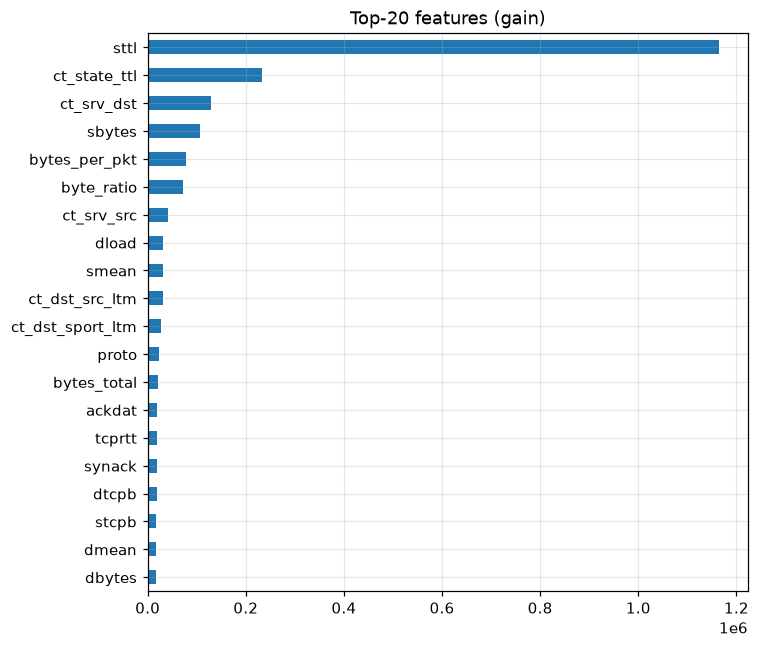

Event #17095 | P(attack)=1.000 | true label=1 | category=Generic


,value,contribution
ct_dst_sport_ltm,7.0000,2.8005
sttl,254.0000,2.6361
ct_srv_src,21.0000,1.2950
byte_ratio,115.0000,0.9627
ct_state_ttl,2.0000,0.9258
ct_src_dport_ltm,7.0000,0.6457


Event #0 | P(attack)=0.863 | true label=0 | category=Normal


,value,contribution
sttl,254.0000,2.1278
ct_dst_sport_ltm,1.0000,-1.5589
ct_state_ttl,2.0000,0.8674
proto,119.0000,-0.7689
sbytes,496.0000,-0.6670
byte_ratio,497.0000,0.5692


In [22]:
imp = pd.Series(lgbm.booster_.feature_importance("gain"), index=Xtr.columns).sort_values(ascending=False)
imp.head(20)[::-1].plot.barh(figsize=(7, 6), title="Top-20 features (gain)"); plt.tight_layout(); show()

def explain_alert(i, X=Xte, df=te_df, top=6):
    """Top features pushing event i towards 'attack' (+) or 'benign' (-)."""
    contrib = lgbm.booster_.predict(X.iloc[[i]], pred_contrib=True)[0][:-1]
    s = pd.Series(contrib, index=X.columns)
    top_idx = s.abs().sort_values(ascending=False).index[:top]
    out = pd.DataFrame({"value": X.iloc[i][top_idx], "contribution": s[top_idx]})
    print(f"Event #{i} | P(attack)={to_prob(p_te['LightGBM'][i]):.3f} | true label={yte[i]}" + (f" | category={df.iloc[i][CAT_COL]}" if CAT_COL else ""))
    return out

# explain the highest-risk true attack and a false positive (if any)
i_tp = int(np.argmax(np.where(yte == 1, p_te["LightGBM"], -1)))
display(explain_alert(i_tp))
fp_idx = np.where((yte == 0) & (p_te["LightGBM"] >= thr["LightGBM"]))[0]
if len(fp_idx): display(explain_alert(int(fp_idx[0])))

## 13. Save the trained SOC engine

In [23]:
OUT = Path("soc_artifacts"); OUT.mkdir(exist_ok=True)
joblib.dump({"dataset": DATASET, "features": FEATURES, "sup_pre": sup_pre, "ae_pre": ae_pre,
             "lgbm": lgbm, "rf": rf, "iso": iso, "ae": ae,
             "thresholds": {**thr, "tier_lo": T_LO, "tier_hi": T_HI}, "hybrid_w": W,
             "real_prevalence": REAL_PREVALENCE,
             "note": "LightGBM scores/thresholds are log-odds (raw_score=True)."}, OUT / f"soc_engine_{DATASET}.joblib")
res_native.to_csv(OUT / f"test_results_native_{DATASET}.csv")
res_real.to_csv(OUT / f"test_results_realistic_{DATASET}.csv")
print("Saved to", OUT.resolve())

Saved to C:\Users\Admin\Downloads\Threat-Hunting-Behavioral-Analysis\soc_artifacts


## 14. 📌 Interpretation guide

1. **Supervised triage (9.1):** the 3-tier table is the headline result: % of attacks caught, % of events a human must touch, and precision of the auto-escalate tier. Compare validation vs test — a drop means the traffic mix shifted and thresholds need re-tuning.
2. **Equal-FPR comparison (9.2):** the fairest comparison of all engines. Look at recall at 0.1 % and 1 % FPR, not at accuracy or ROC-AUC.
3. **Unsupervised engines:** Isolation Forest vs Autoencoder — which gives more recall at the same FPR? If one is near zero, it is not worth running on this data.
4. **Threshold optimisation (7 and 7.2):** show how the optimum moves with `COST_FN` and prevalence. A bigger cost of a miss pushes the threshold *down* (more alerts, more recall); rarer attacks push it *up*.
5. **Hybrid (8):** only claim a benefit if the chosen `w` is below 1.0 *and* the hybrid wins in 9.2.
6. **Zero-day (11):** compare the blind supervised row to the "(seen families)" reference to quantify the cost of novelty.
7. **Limitations:** UNSW-NB15 is synthetic and its train/test mix differs, so supervised scores are optimistic compared with real networks; the random train/validation split also puts near-duplicate flows on both sides. Re-tune thresholds on recent data and monitor drift.

---
## 🔁 How to switch to the CERT insider-threat dataset
1. Download CERT r4.2 (or r5.x) and place `logon.csv, device.csv, file.csv, email.csv, http.csv` in `CERT_DIR`, and `answers/insiders.csv` in `CERT_ANSWERS`.
2. In **Section 1** set `DATASET = "CERT"` (and `CERT_VERSION` to match `insiders.csv`).
3. Set `REAL_PREVALENCE` to roughly the true insider rate (≈ 0.005) and raise `COST_FN`.
4. *Restart & run all.* Everything downstream works unchanged because the adapter returns the same `(train, test)` contract. Section 11 is skipped (no category column); add an `insider scenario` column in `load_cert` and set `category_col` in `DATASETS` to enable it.
5. The CERT adapter streams the big `http.csv` in chunks; the first load can take several minutes — consider caching the user-day table with `daily.to_parquet(...)`.